# Teks — Topik Dinamis (topik berubah dari waktu ke waktu)
**Kapan dipakai:** pola Satria Data 2022: kumpulan teks bertanggal → topik apa saja, kapan
naik/turun, dan bagaimana kata kuncinya bergeser per periode.

**Langkah:**
1. Satu model topik (NMF) untuk semua teks → tiap teks diberi topik.
2. Proporsi topik per bulan (tren).
3. Kata kunci tiap topik per kuartal (pergeseran isi topik).

**Data demo:** TweetTopic (tweet Inggris 2019–2021). Label hanya untuk membandingkan (NMI).

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import normalized_mutual_info_score

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/text/topik_waktu"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/tweet_topic.csv"

TEXT_COL = "text"
DATE_COL = "date"
LABEL_COL = "label_name"   # hanya untuk membandingkan, boleh tidak ada saat lomba
N_TOPICS = 10
N_TOP_WORDS = 8
MIN_TEXTS = 5              # kuartal dengan < 5 teks untuk satu topik dilewati
SEED = 42

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV, parse_dates=[DATE_COL])
print(data.shape)
print(data[DATE_COL].min(), "s.d.", data[DATE_COL].max())
data.head()

(7768, 3)
2019-09-08 00:00:00 s.d. 2021-08-29 00:00:00


,date,text,label_name
0,2019-09-08,The {@Clinton LumberKings@} beat the {@Cedar R...,sports
1,2019-09-08,T-33 days until #saveagainstfear2019 One of t...,gaming|sports
2,2019-09-08,Game Day! Wish we could see {@LaAdrian Waddle...,sports
3,2019-09-08,Game day!!! {@Ito Smith@} #NFL100 #InBrotherho...,sports
4,2019-09-08,Baker Mayfield and OBJ arrive for Game 1 at Fi...,celebrity_&_pop_culture|sports


## EDA: jumlah teks per bulan

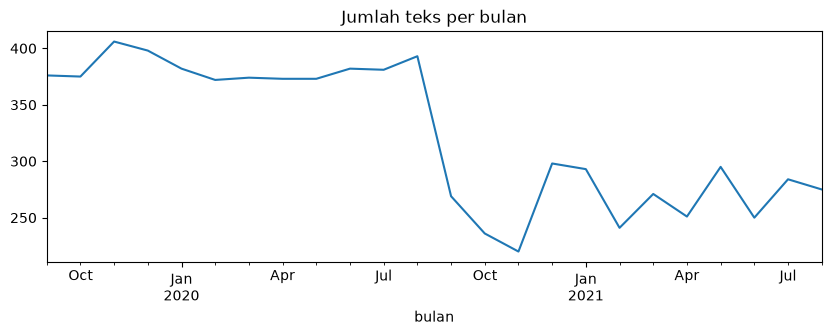

In [4]:
data["bulan"] = data[DATE_COL].dt.to_period("M")
data["kuartal"] = data[DATE_COL].dt.to_period("Q")
texts_per_month = data.groupby("bulan").size()
texts_per_month.plot(figsize=(10, 3))
plt.title("Jumlah teks per bulan")
plt.show()

## Bersihkan teks
Penanda `{{USERNAME}}`, `{{URL}}`, link, dan mention dibuang; sisakan huruf saja.

In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\{\{username\}\}|\{\{url\}\}|http\S+|@\w+", " ", text)
    text = re.sub(r"[{}@]", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return text


print(clean_text("Great game by {{USERNAME}} tonight!! http://t.co/x"))
data["bersih"] = data[TEXT_COL].fillna("").apply(clean_text)

great game by   tonight    


## Model
NMF memakai `TfidfVectorizer`, LDA memakai `CountVectorizer`.
Pilih SATU pasangan: hapus `#` di dua baris yang ingin dipakai, beri `#` pada pasangan lain.

In [6]:
vectorizer = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.4, ngram_range=(1, 2))
model = NMF(n_components=N_TOPICS, init="nndsvda", random_state=SEED, max_iter=400)
# vectorizer = CountVectorizer(stop_words="english", min_df=5, max_df=0.4)
# model = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch",
#                                   random_state=SEED)

X = vectorizer.fit_transform(data["bersih"])
doc_topics = model.fit_transform(X)
data["topik"] = doc_topics.argmax(axis=1)

vocabulary = vectorizer.get_feature_names_out()
topic_names = []
for topic_number in range(N_TOPICS):
    top_columns = np.argsort(model.components_[topic_number])[::-1][:N_TOP_WORDS]
    top_words = vocabulary[top_columns]
    topic_names.append(f"T{topic_number}: " + ", ".join(top_words[:3]))
    print("topik", topic_number, ":", ", ".join(top_words))

topik 0 : video, music, music video, official, official music, new music, feat, watch
topik 1 : game, vs, win, state, football, league, final, live
topik 2 : new, album, new album, song, music, new music, spotify, check new
topik 3 : love, thank, love love, really, song, really love, life, hope
topik 4 : climate, change, climate change, news, thunberg, world, greta, greta thunberg
topik 5 : time, just, like, don, good, news, people, know
topik 6 : just, check, poshmark, just added, shopmycloset, added, closet, check just
topik 7 : happy, day, easter, year, mother, women, mothers, mother day
topik 8 : styles, sugar, watermelon, watermelon sugar, harry, harry styles, watermelonsugar, styles watermelon
topik 9 : sign, petition, sign petition, org, petition org, united, states, united states


## Evaluasi: cocok dengan label manusia? (hanya bila label ada)
Satu tweet bisa punya beberapa label ("a|b"), ambil label pertama saja.

In [7]:
first_label = data[LABEL_COL].fillna("tanpa_label").str.split("|").str[0]
print("NMI topik vs label:", round(normalized_mutual_info_score(first_label, data["topik"]), 4))
pd.crosstab(data["topik"], first_label).T

NMI topik vs label: 0.1453


topik,0,1,2,3,4,5,6,7,8,9
label_name,,,,,,,,,,
arts_&_culture,9,14,31,20,5,138,17,99,3,10
business_&_entrepreneurs,0,12,24,7,9,229,32,22,0,21
celebrity_&_pop_culture,104,62,139,129,22,419,45,72,79,53
diaries_&_daily_life,7,21,58,70,9,404,29,193,4,44
family,1,7,5,10,1,42,1,34,0,5
fashion_&_style,2,3,4,2,0,24,27,5,0,0
film_tv_&_video,101,48,63,31,13,369,50,30,17,24
fitness_&_health,1,28,22,6,1,130,6,16,0,18
food_&_dining,1,6,3,3,1,30,3,17,0,1


## Tren: proporsi topik per bulan

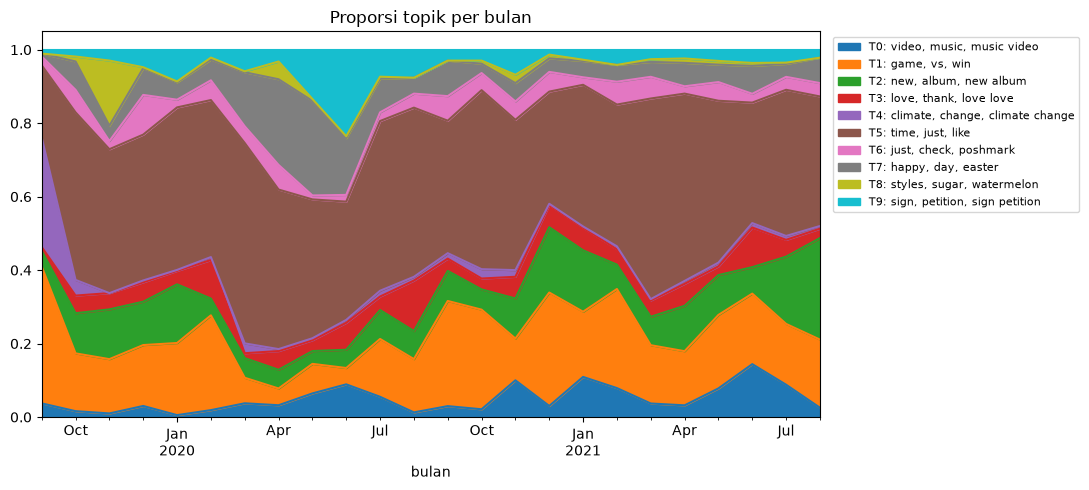

In [8]:
topic_per_month = pd.crosstab(data["bulan"], data["topik"], normalize="index")
topic_per_month.columns = topic_names
topic_per_month.to_csv("topik_per_bulan.csv")
topic_per_month.plot.area(figsize=(11, 5), cmap="tab10")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.title("Proporsi topik per bulan")
plt.tight_layout()
plt.show()

## Topik yang naik / turun
Rata-rata 6 bulan terakhir dikurangi rata-rata 6 bulan pertama.

In [9]:
change = topic_per_month.iloc[-6:].mean() - topic_per_month.iloc[:6].mean()
print(change.sort_values().round(3))

T4: climate, change, climate change   -0.051
T1: game, vs, win                     -0.041
T8: styles, sugar, watermelon         -0.027
T6: just, check, poshmark             -0.011
T9: sign, petition, sign petition     -0.007
T3: love, thank, love love             0.002
T7: happy, day, easter                 0.005
T2: new, album, new album              0.038
T5: time, just, like                   0.044
T0: video, music, music video          0.048
dtype: float64


## Pergeseran kata kunci: tiap topik per kuartal
Kata kunci = rata-rata TF-IDF teks bertopik itu di kuartal itu.

In [10]:
quarter_words = pd.DataFrame()
for quarter in sorted(data["kuartal"].unique()):
    for topic_number in range(N_TOPICS):
        rows = (data["kuartal"] == quarter) & (data["topik"] == topic_number)
        rows = rows.to_numpy()
        if rows.sum() < MIN_TEXTS:
            continue
        mean_weight = np.asarray(X[rows].mean(axis=0)).ravel()
        top_columns = np.argsort(mean_weight)[::-1][:5]
        quarter_words.loc[str(quarter), f"T{topic_number}"] = ", ".join(vocabulary[top_columns])
quarter_words.to_csv("kata_kunci_per_kuartal.csv")
quarter_words[["T0", "T1", "T2"]]

,T0,T1,T2
2019Q3,"video, music video, music, new music, new","game, vs, win, football, season","new, york, new york, report, looks"
2019Q4,"video, music, watch video, watch, proof","browns, game, joshua, anthony joshua, anthony","new, album, new album, spotify, distributed live"
2020Q1,"video, music, music video, official, official ...","game, win, bowl, super bowl, super","new, year, new year, album, decade"
2020Q2,"video, music video, music, official, official ...","sports, live sports, live, nascar, game","new, new york, york, york times, times"
2020Q3,"nowplaying, music, video, official, submit","league, game, premier league, premier, win","new, nowplaying, song, new video, rick ross"
2020Q4,"music, video, music video, official, official ...","state, ohio, ohio state, game, football","new, eve, new year, new years, years eve"
2021Q1,"music, video, music video, official, official ...","second, bowl, super bowl, super, chiefs","new, song, new years, year, new year"
2021Q2,"video, music, music video, official, official ...","league, city, cup, final, chelsea","new, new music, album, music, song"
2021Q3,"video, official, music, music video, new music","win, league, head, game, nba","new, album, music, permission dance, permission"


## Submission: topik tiap teks
Format soal minta kolom lain? Tambah satu baris `submission["nama"] = ...`.

In [11]:
names_per_text = []
for topic_number in data["topik"]:
    names_per_text.append(topic_names[topic_number])

submission = pd.DataFrame()
submission["date"] = data[DATE_COL].dt.date
submission["text"] = data[TEXT_COL]
submission["topik"] = data["topik"]
submission["nama_topik"] = names_per_text
submission.to_csv("submission.csv", index=False)
submission.head()

,date,text,topik,nama_topik
0,2019-09-08,The {@Clinton LumberKings@} beat the {@Cedar R...,1,"T1: game, vs, win"
1,2019-09-08,T-33 days until #saveagainstfear2019 One of t...,1,"T1: game, vs, win"
2,2019-09-08,Game Day! Wish we could see {@LaAdrian Waddle...,1,"T1: game, vs, win"
3,2019-09-08,Game day!!! {@Ito Smith@} #NFL100 #InBrotherho...,1,"T1: game, vs, win"
4,2019-09-08,Baker Mayfield and OBJ arrive for Game 1 at Fi...,1,"T1: game, vs, win"
